# 01 — Exploratory Data Analysis

**Input:** `data/raw/dataset.csv` (3.2 GB, 542,947 Franco/Egyptian document pairs)

**Outputs:**
- `data/interim/dataset.parquet`: typed copy with null rows dropped (loads in seconds)
- `data/interim/doc_stats.parquet`: per-document features, used by `02_splits` for stratification
- `reports/figures/*.png`

Questions we answer:
1. How big and how long are the examples? Are they sentences or documents?
2. Can documents be aligned line by line, and what length ratio does that give?
3. What is the noise: Arabic-script inputs, digit conventions, diacritics, rewritten targets?
4. How ambiguous is the word-level mapping, and how many spelling variants are there? This tells us how much context the model needs.

In [ ]:
import collections
import re
import time

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

# from franco_arabic import paths
# from franco_arabic.text import ARABIC_RE, nonempty_lines

pl.Config.set_tbl_rows(30)
pl.Config.set_fmt_str_lengths(120)
SEED = 454

ModuleNotFoundError: No module named 'polars'

## 1. Load raw CSV → parquet
The CSV has multi-line quoted fields, so we let polars parse it, read every column as a string first, then cast `ID`.

In [ ]:
t = time.time()
raw = pd.read_csv("data/raw/dataset.csv", infer_schema_length=0)
raw = raw.rename({raw.columns[0]: "ID"})  # first header has a UTF-8 BOM
raw = raw.with_columns(pl.col("ID").cast(pl.Int64))
print(f"loaded {raw.shape} in {time.time() - t:.1f}s; columns = {raw.columns}")
print("null counts:", raw.null_count().row(0, named=True))
print("ID unique:", raw["ID"].n_unique() == raw.height, "range", raw["ID"].min(), raw["ID"].max())

loaded (542947, 3) in 2.9s; columns = ['ID', 'Franco', 'Egyptian']
null counts: {'ID': 0, 'Franco': 11, 'Egyptian': 1}
ID unique: True range 1 542947


In [3]:
raw.filter(pl.any_horizontal(pl.all().is_null()))

ID,Franco,Egyptian
i64,str,str
204281,null,"""دراسات اجتماعية مستوى 5 بعض الأنشطة المقترحة عند دراسة موضوع مثير للجدل وعاطفي للغاية، من المهم وضع بعض الحدود والقواعد …"
237810,null,"""البرمجة الوظيفية ليها نظرية احتياطية أنيقة جدًا اسمها حساب لامبدا ومتغيراتها. هل فيه حاجة زي كده للبرمجة الكائنية؟ إيه ه…"
239552,null,"""فيه مخاطر كتيرة مرتبطة بالغازات المضغوطة، زي إزاحة الأكسجين، والحرايق، والانفجارات، والتأثيرات السامة من غازات معينة، كم…"
241525,null,"""طلاب الصف السابع في مدرسة جورني الإعدادية عملوا حفلة شواء تقليدية للأسماك على الطريقة الأصلية بتاعة السكان الأصليين في ا…"
259428,"""ana 3ayez a2ool en el-7ayah de mesh sahelah, bas fe nafsa el-wa2t, momken teb2a gameela awii law 3ayeshha bel-7ob w el-t…",null
262571,null,"""في نوفمبر ٢٠١٩، طلبنا من كل أطفالنا من سنة تالتة لحد سنة ساتة إنهم يشاركوا في استطلاع رأي عن القراية. والسبب ورا الاستبي…"
320377,null,"""الرعاية والوقاية العامة من السرطان •آخر تحديث: ١٦ أغسطس ٢٠٢٢ السرطان هو مجموعة من الأمراض التي تنقسم فيها الخلايا غير ال…"
422007,null,"""التهاب وتر أخيل - الأعراض والأسباب والعلاج وتر أخيل هو وتر قوي على شكل حبل يربط العضلات في الجزء الخلفي من ساقك السفلية …"
446387,null,"""في عددي يناير وفبراير 1849 من مجلته ""نيو راينش زايتونج""، نشر كارل ماركس مقالات تدعو إلى إبادة أعراق كاملة في أوروبا. تم …"


A handful of rows have an empty side. They can't be used for training, so we drop them.

In [4]:
df = raw.drop_nulls()
df.write_parquet(paths.DATASET_PARQUET)
del raw
print(df.height, "rows ->", paths.DATASET_PARQUET)

542935 rows -> /home/moalkhateeb/Uni/CMPS454 Natural Language Processing/Project/franco-arabic-converter/data/interim/dataset.parquet


## 2. Sample pairs

In [5]:
for row in df.sample(3, seed=SEED).iter_rows(named=True):
    print(f"=== ID {row['ID']}")
    print(row["Franco"][:500])
    print("---")
    print(row["Egyptian"][:450], "\n")

=== ID 407150
elta7yez wel tanmeet wel tameyeez

eh momken yekoon youm bedoon ma te7'od 7okm 3ala 7ad? 2a2id la2. sahel gedan ennak te7'od 7okm 3ala elnas men 3'eer ma te2sad. fe ketab 3elm elnafs elterbowy, aneeta wolffek betwasf elta7yez 3ala enno "7okm masbe2 aw ta3meem ghayr manti2y 3ala fegha kameela men elnas" (wolffek, 2008). elta7yez moshkela kbeera fe 7ayateena elyawmeyya. bey7sal 7awlena kol youm. elta7yez momken yekoon 7aga eijabeya aw salbeya. 3adaan beykoon salby, bey2alel men elnas, w mesh dayma
---
التحيز والتنميط والتمييز
هل مر يوم بدون ما تحكم على حد؟ أكيد لأ. سهل جداً إنك تحكم على الناس من غير ما تقصد. في كتاب علم النفس التربوي، أنيتا وولفك بتوصف التحيز على إنه "حكم مسبق أو تعميم غير منطقي على فئة كاملة من الناس" (وولفك، 2008). التحيز مشكلة كبيرة في حياتنا اليومية. بيحصل حوالينا كل يوم. التحيز ممكن يكون حاجة إيجابية أو سلبية. عادةً بيكون سلبي، بيقلل من الناس، ومش دايماً بيكون حقيقي. التمييز هو "المعاملة أو التصرف غير العادل تجاه فئات معي 

=== ID 11206
- ya hala ya ha

## 3. Per-document statistics

In [6]:
AR = ARABIC_RE.pattern
stats = df.select(
    "ID",
    f_chars=pl.col("Franco").str.len_chars(),
    e_chars=pl.col("Egyptian").str.len_chars(),
    f_words=pl.col("Franco").str.split(" ").list.len(),
    e_words=pl.col("Egyptian").str.split(" ").list.len(),
    f_lines=pl.col("Franco").str.count_matches("\n") + 1,
    e_lines=pl.col("Egyptian").str.count_matches("\n") + 1,
    f_arabic_ratio=pl.col("Franco").str.count_matches(AR) / pl.col("Franco").str.len_chars(),
    e_arabic_ratio=pl.col("Egyptian").str.count_matches(AR) / pl.col("Egyptian").str.len_chars(),
    e_latin_ratio=pl.col("Egyptian").str.count_matches(r"[A-Za-z]") / pl.col("Egyptian").str.len_chars(),
    e_indic_digits=pl.col("Egyptian").str.count_matches(r"[٠-٩]"),
    e_western_digits=pl.col("Egyptian").str.count_matches(r"[0-9]"),
    e_diacritics=pl.col("Egyptian").str.count_matches(r"[ً-ْ]"),
).with_columns(char_ratio=pl.col("e_chars") / pl.col("f_chars"))

Q = [0.0, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999, 1.0]
pl.DataFrame(
    {"quantile": Q} | {c: [stats[c].quantile(q) for q in Q]
                       for c in ["f_chars", "e_chars", "f_words", "e_words", "f_lines", "e_lines", "char_ratio"]}
)

quantile,f_chars,e_chars,f_words,e_words,f_lines,e_lines,char_ratio
f64,f64,f64,f64,f64,f64,f64,f64
0.0,4.0,4.0,1.0,1.0,1.0,1.0,0.07489
0.01,395.0,341.0,60.0,55.0,1.0,1.0,0.75363
0.05,716.0,604.0,108.0,98.0,3.0,2.0,0.772113
0.25,1397.0,1169.0,218.0,197.0,8.0,7.0,0.799542
0.5,1993.0,1662.0,314.0,279.0,13.0,11.0,0.826037
0.75,3111.0,2595.0,476.0,426.0,18.0,17.0,0.878391
0.95,4658.0,4478.0,731.0,731.0,35.0,31.0,1.021099
0.99,5015.0,5286.0,861.0,863.0,54.0,48.0,1.20988
0.999,5326.0,5842.0,919.0,947.0,85.0,78.0,2.399351


In [7]:
print(f"total Franco chars:   {stats['f_chars'].sum() / 1e9:.2f} G")
print(f"total Egyptian chars: {stats['e_chars'].sum() / 1e9:.2f} G")
print("exact duplicate pairs:", df.height - df.select("Franco", "Egyptian").unique().height)
print("duplicate Franco:", df.height - df["Franco"].n_unique(), "| duplicate Egyptian:", df.height - df["Egyptian"].n_unique())

total Franco chars:   1.25 G
total Egyptian chars: 1.09 G


exact duplicate pairs: 14


duplicate Franco: 15 | duplicate Egyptian: 39


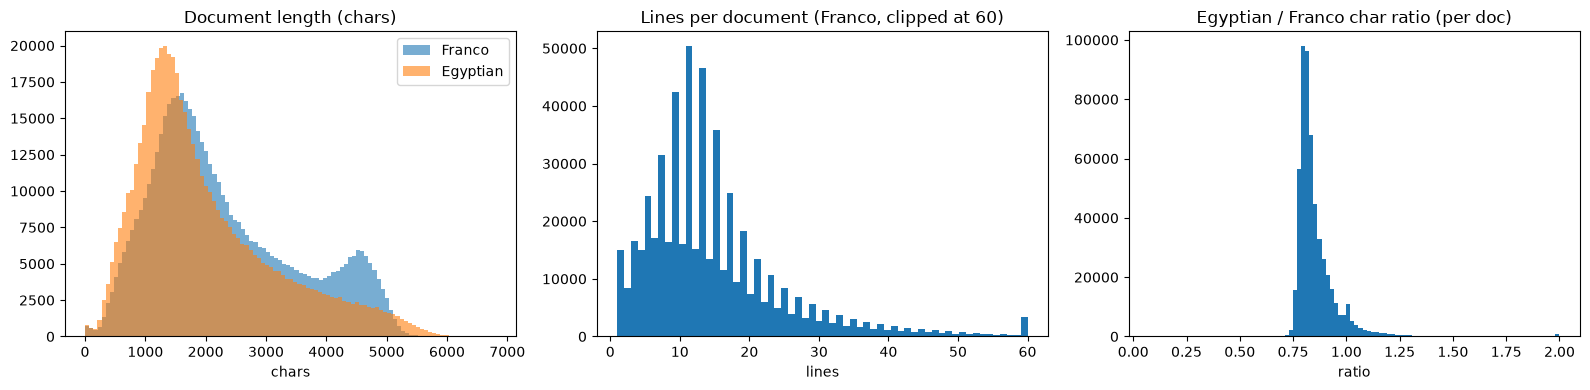

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(stats["f_chars"].clip(upper_bound=7000), bins=100, alpha=.6, label="Franco")
axes[0].hist(stats["e_chars"].clip(upper_bound=7000), bins=100, alpha=.6, label="Egyptian")
axes[0].set(title="Document length (chars)", xlabel="chars"); axes[0].legend()
axes[1].hist(stats["f_lines"].clip(upper_bound=60), bins=60)
axes[1].set(title="Lines per document (Franco, clipped at 60)", xlabel="lines")
axes[2].hist(stats["char_ratio"].clip(0, 2), bins=100)
axes[2].set(title="Egyptian / Franco char ratio (per doc)", xlabel="ratio")
plt.tight_layout(); plt.savefig(paths.FIGURES / "01_lengths.png", dpi=120); plt.show()

**Takeaway:** the examples are **multi-line documents** (about 2.3k chars and 14 lines on average), not the short sentences shown in the project PDF. A model can't take a whole document in one pass, so we will work on lines or sentences and stitch the output back together.

## 4. Script mix and noise

In [9]:
n = stats.height
summary = {
    "Franco mostly Arabic script (>50%)": (stats["f_arabic_ratio"] > .5).sum(),
    "Franco contains any Arabic script": (stats["f_arabic_ratio"] > 0).sum(),
    "Egyptian <50% Arabic script": (stats["e_arabic_ratio"] < .5).sum(),
    "Egyptian has Latin letters": (stats["e_latin_ratio"] > 0).sum(),
    "Egyptian has Arabic-Indic digits ٠-٩": (stats["e_indic_digits"] > 0).sum(),
    "Egyptian has Western digits 0-9": (stats["e_western_digits"] > 0).sum(),
    "Egyptian has diacritics (tashkeel)": (stats["e_diacritics"] > 0).sum(),
}
pl.DataFrame({"property": list(summary), "docs": list(summary.values()),
              "pct": [round(v / n * 100, 2) for v in summary.values()]})

property,docs,pct
str,i64,f64
"""Franco mostly Arabic script (>50%)""",18276,3.37
"""Franco contains any Arabic script""",92756,17.08
"""Egyptian <50% Arabic script""",827,0.15
"""Egyptian has Latin letters""",179169,33.0
"""Egyptian has Arabic-Indic digits ٠-٩""",64216,11.83
"""Egyptian has Western digits 0-9""",361620,66.6
"""Egyptian has diacritics (tashkeel)""",452164,83.28


In [10]:
tot_e = stats["e_chars"].sum()
print(f"Arabic-Indic digits = {stats['e_indic_digits'].sum() / tot_e * 100:.3f}% of target chars "
      f"(Western: {stats['e_western_digits'].sum() / tot_e * 100:.3f}%)")
print(f"Diacritics          = {stats['e_diacritics'].sum() / tot_e * 100:.3f}% of target chars")

Arabic-Indic digits = 0.079% of target chars (Western: 0.727%)
Diacritics          = 0.233% of target chars


Is the digit style predictable? Look at what the Franco side contains when the target uses Arabic-Indic digits:

In [11]:
ind = df.join(stats.select("ID", "e_indic_digits"), on="ID").filter(pl.col("e_indic_digits") > 0).sample(2000, seed=SEED)
print("Franco has Arabic-Indic digits:", ind["Franco"].str.contains(r"[٠-٩]").sum(), "/ 2000")
print("Franco has Western digits:     ", ind["Franco"].str.contains(r"[0-9]").sum(), "/ 2000")

Franco has Arabic-Indic digits: 100 / 2000
Franco has Western digits:      1956 / 2000


**Takeaway:** about 12% of documents switch to Arabic-Indic digits even though the Franco has Western ones. Nothing in the input predicts this, so we always output Western digits (the majority style). Diacritics are about 0.2% of characters, a small error floor we accept.

What does the target look like when the "Franco" is already in Arabic script?

In [12]:
for row in df.join(stats.select("ID", "f_arabic_ratio"), on="ID").filter(pl.col("f_arabic_ratio") > .5).sample(2, seed=SEED).iter_rows(named=True):
    print("FRANCO  :", row["Franco"][:250].replace("\n", " | "))
    print("EGYPTIAN:", row["Egyptian"][:250].replace("\n", " | "), "\n")

FRANCO  : آخِر تَعديل: 9 ديسمبر 2013 بِواسطة روب ريسيد | الكَلِمات المِفتاحية: شِعارات النِبالة | الرَوابِط: صَفحة FOTW الرئيسية | بَحث | إخلاء المَسؤولية وحُقوق النَشر | تواصَل مَعنا | المَرايَا | هَبَدأ هاي السِلسِلة بـ"الصبغات" (أي الألوان) المُستَخدَمة في شِعارا
EGYPTIAN: آخر تعديل: 9 ديسمبر 2013 بواسطة روب ريسيد | الكلمات المفتاحية: شعارات النبالة | الروابط: صفحة FOTW الرئيسية | بحث | إخلاء المسؤولية وحقوق النشر | تواصل معنا | المرايا | سأبدأ هذه السلسلة بـ"الصبغات" (أي الألوان) المستخدمة في شعارات النبالة. | تنقسم الصبغات إ 

FRANCO  : ايه هو الاسبستوس؟ | الاسبستوس ده اسم لمجموعة معادن بتتميز بأليافها الطويلة والرفيعة والقابلة للانفصال. الاسبستوس اللي أليافه منفصلة بتبقى قوية ومرنة لدرجة انها ممكن تتنسج. ألياف الاسبستوس مقاومة للحرارة، وده بيخليها مفيدة جداً في الصناعة. | الاسبستوس بيت
EGYPTIAN: ايه هو الاسبستوس؟ | الاسبستوس ده اسم لمجموعة من المعادن اللي بتتميز بأليافها اللي طويلة ورفيعة وقابلة للانفصال. الاسبستوس اللي أليافه منفصلة قوية ومرنة لدرجة انها ممكن تتنسج. ألياف الاسبس

These are near-copies, sometimes with hamza fixes or light rewording. We keep them in training so the model learns to pass Arabic-script input through, and flag them so we can downweight them.

## 5. Character inventories (30k-doc sample)

In [13]:
sample = df.sample(30_000, seed=SEED)
inv = {}
for col in ["Franco", "Egyptian"]:
    c = collections.Counter()
    for t in sample[col]:
        c.update(t)
    inv[col] = c
    total = sum(c.values())
    cov = np.cumsum(sorted(c.values(), reverse=True)) / total
    print(f"{col}: {len(c)} distinct chars; top-100 cover {cov[99] * 100:.3f}%, top-200 cover {cov[199] * 100:.4f}%")
    print("  top 80:", " ".join(f"{k!r}" for k, _ in c.most_common(80)))
    rare = [k for k, v in c.items() if v / total < 1e-5]
    print(f"  {len(rare)} rare chars (<1e-5), e.g.:", "".join(rare[:80]), "\n")

Franco: 1003 distinct chars; top-100 cover 99.829%, top-200 cover 99.9947%
  top 80: ' ' 'a' 'e' 'l' 't' 'm' 'n' 'o' 's' 'y' 'h' 'r' 'b' 'd' '3' 'w' 'k' 'f' '2' '7' '-' 'g' '.' ',' 'i' 'z' '\n' "'" 'ا' '5' 'ل' 'q' 'ي' 'j' 'u' 'E' 'م' 'و' '"' 'ن' '0' 'ت' '1' 'ر' '6' 'c' 'ب' 'A' 'M' 'د' ':' 'ع' 'p' 'ة' '9' 'س' ')' 'B' '(' 'ف' 'ك' 'S' 'ه' 'W' '?' 'ق' 'D' 'L' 'ح' 'T' 'F' '8' 'ج' '4' '،' 'C' 'K' '!' 'H' 'ش'
  869 rare chars (<1e-5), e.g.: ـ@ّ地支；十二歲星ìī攝提èíηö午©üÄäàćęźæ»😊🙏🏻💪🤲🤩🌟🙋‍♀️🌹🌍💕ڤ~–×·\ˌəˈȯē—^µΛτ٩٣٦🌷🇪🇬❤♉∠°♒♋♌♑½٤٧®#😋ɪ 



Egyptian: 1285 distinct chars; top-100 cover 99.795%, top-200 cover 99.9923%
  top 80: ' ' 'ا' 'ل' 'ي' 'م' 'و' 'ن' 'ت' 'ر' 'ب' 'ع' 'ة' 'د' 'ك' 'ف' 'س' 'ه' 'ق' 'ح' 'أ' 'ج' '.' '،' 'ش' 'ط' 'ص' 'خ' '\n' 'ز' 'إ' 'ى' 'ض' 'غ' 'ث' 'ئ' 'ء' 'ذ' '"' 'ً' 'ظ' '-' '0' '1' '2' ':' ')' '(' 'e' 'ؤ' '؟' '5' 'آ' '9' '3' 'a' '4' '8' 't' 'o' 'i' '!' '6' 'r' '7' 'n' 's' 'l' '/' 'c' 'S' '|' 'A' '؛' 'C' 'm' 'ّ' 'd' 'h' 'p' 'u'
  1143 rare chars (<1e-5), e.g.: Z×ٍ地支十二歲星ìī攝提èíηö午©üÄäàćęź?æq»😊🙏🏻💪🤲🤩🌟🙋‍♀️🌹🌍💕ڤ~–’پ·\ˌəˈȯē—µΛτ🌷🇪🇬❤♉∠°♒♋♌♑“”↩;½®^😋‘ 



**Takeaway:** about 100 characters cover more than 99.9% of each side. The long tail (emoji, CJK, symbols) gets copied through unchanged with a placeholder or copy mechanism rather than taking up vocabulary slots. Arabizi digits (`2 3 5 6 7 8 9`) and `'` are among the most frequent Franco characters, so normalization must keep them.

## 6. Line alignment

In [14]:
def line_alignment_stats(frame: pl.DataFrame):
    rows = []
    for doc_id, f, e in frame.select("ID", "Franco", "Egyptian").iter_rows():
        fl, el = nonempty_lines(f), nonempty_lines(e)
        aligned = len(fl) == len(el)
        rows.append((doc_id, aligned, f.count("\n") == e.count("\n")))
        if aligned:
            for a, b in zip(fl, el):
                line_rows.append((len(a), len(b), len(a.split()), len(b.split())))
    return pl.DataFrame(rows, schema=["ID", "aligned_nonempty", "aligned_raw"], orient="row")

line_rows = []
latin_docs = df.join(stats.select("ID", "f_arabic_ratio"), on="ID").filter(pl.col("f_arabic_ratio") <= .05)
al = line_alignment_stats(latin_docs.sample(40_000, seed=SEED))
lines = pl.DataFrame(line_rows, schema=["f_len", "e_len", "f_w", "e_w"], orient="row").with_columns(
    ratio=pl.col("e_len") / pl.col("f_len"))
print(f"same raw newline count:        {al['aligned_raw'].mean():.3f}")
print(f"same NON-EMPTY line count:     {al['aligned_nonempty'].mean():.3f}")
print(f"aligned lines sampled:         {lines.height}")
print(f"line ratio in [0.6, 1.1]:      {lines['ratio'].is_between(.6, 1.1).mean():.3f}")
print(f"lines with equal word count:   {(lines['f_w'] == lines['e_w']).mean():.3f}")
print("line length (chars) quantiles:", {q: int(lines['f_len'].quantile(q)) for q in [.5, .9, .95, .99, .999]})
print(f"lines > 256 chars: {(lines['f_len'] > 256).mean():.3f}   > 512: {(lines['f_len'] > 512).mean():.4f}")

same raw newline count:        0.691
same NON-EMPTY line count:     0.886
aligned lines sampled:         350446
line ratio in [0.6, 1.1]:      0.994
lines with equal word count:   0.282
line length (chars) quantiles: {0.5: 174, 0.9: 429, 0.95: 549, 0.99: 901, 0.999: 1819}
lines > 256 chars: 0.318   > 512: 0.0611


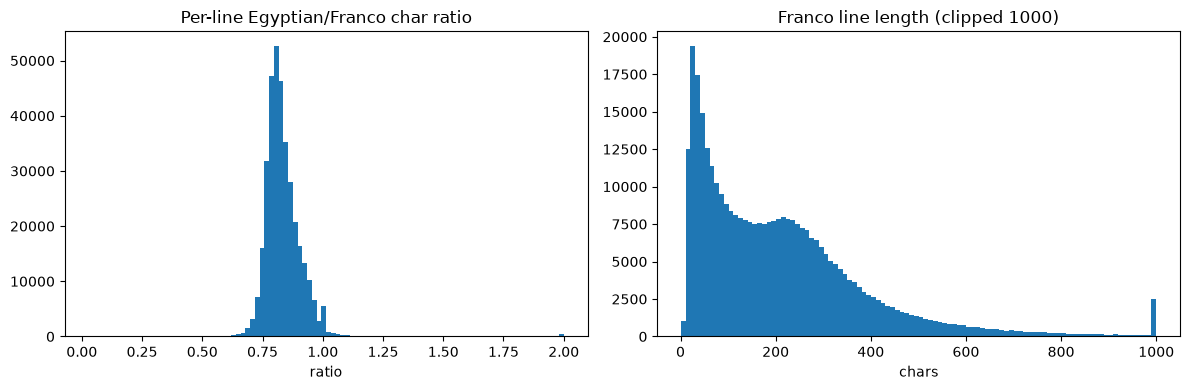

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(lines["ratio"].clip(0, 2), bins=100); axes[0].set(title="Per-line Egyptian/Franco char ratio", xlabel="ratio")
axes[1].hist(lines["f_len"].clip(upper_bound=1000), bins=100); axes[1].set(title="Franco line length (clipped 1000)", xlabel="chars")
plt.tight_layout(); plt.savefig(paths.FIGURES / "01_line_alignment.png", dpi=120); plt.show()

**Takeaway:**
- About 89% of documents align line by line once blank lines are ignored, and the per-line length ratio is tight (around 0.82). That gives us millions of clean parallel lines.
- Only about 28% of lines have equal word counts, because clitics join words (`w 3ayez` → `وعايز`, `l-l-syatra` → `للسيطرة`). So word-level tagging is ruled out; we need sequence-to-sequence over characters or subwords.
- About 30% of lines exceed 256 chars, so long lines are split further at sentence punctuation.

## 7. Word-level ambiguity and spelling variation
On lines with equal word counts we pair words by position. This is approximate, but enough to measure how ambiguous the mapping is.

In [16]:
fwd = collections.defaultdict(collections.Counter)
strip_f, strip_e = '.,?!:"()', '.,?!:"()،؟'
for f, e in latin_docs.sample(60_000, seed=SEED + 1).select("Franco", "Egyptian").iter_rows():
    for a, b in zip(f.split("\n"), e.split("\n")):
        aw, bw = a.split(), b.split()
        if aw and len(aw) == len(bw):
            for x, y in zip(aw, bw):
                fwd[x.lower().strip(strip_f)][y.strip(strip_e)] += 1
tokens = sum(sum(c.values()) for c in fwd.values())
majority = sum(c.most_common(1)[0][1] for c in fwd.values())
print(f"word-majority mapping accuracy: {majority / tokens:.3f} ({tokens:,} tokens, {len(fwd):,} Franco types)")
for w in ["ana", "en", "eh", "enta", "elly", "3la", "fe", "momken", "keda", "bas", "law", "dah", "3ashan"]:
    c = fwd[w]; s = sum(c.values())
    print(f"{w:>8} ({s:>6}):", ", ".join(f"{k} {v / s:.2f}" for k, v in c.most_common(4)))

word-majority mapping accuracy: 0.847 (2,340,051 tokens, 457,469 Franco types)
     ana ( 10139): أنا 0.91, انا 0.03, مش 0.00, بحب 0.00
      en ( 16457): إن 0.78, ان 0.07, أن 0.03, من 0.01
      eh (  7936): إيه 0.77, ايه 0.15, ما 0.02, اللي 0.00
    enta (   999): انت 0.47, إنت 0.24, أنت 0.16, انتا 0.01
    elly ( 24844): اللي 0.82, التي 0.02, اللى 0.02, الذي 0.01
     3la ( 11786): على 0.93, الرغم 0.00, في 0.00, من 0.00
      fe ( 65299): في 0.87, فيه 0.02, فى 0.01, هناك 0.00
  momken ( 10874): ممكن 0.82, يمكن 0.02, قد 0.01, يكون 0.01
    keda (  3517): كده 0.75, كدة 0.09, ذلك 0.03, كذا 0.00
     bas (  6379): بس 0.82, لكن 0.03, فقط 0.02, بص 0.01
     law (  4130): لو 0.79, إذا 0.09, كان 0.01, ولو 0.01
     dah ( 14106): ده 0.89, وده 0.01, هذا 0.01, ذلك 0.00
  3ashan (  8560): عشان 0.81, علشان 0.04, لأن 0.03, لأنها 0.01


In [17]:
inv_map = collections.defaultdict(collections.Counter)
for x, c in fwd.items():
    for y, v in c.items():
        inv_map[y][x] += v
for y in ["عشان", "يعني", "ممكن", "كمان", "اللي", "حاجة", "الأطفال"]:
    print(y, inv_map[y].most_common(8))

عشان [('3ashan', 6904), ('3shan', 5830), ('el', 25), ('ashan', 22), ('w', 12), ('keda', 11), ("3'shan", 11), ('fe', 8)]
يعني [('ya3ny', 4236), ('y3ny', 575), ('ye3ny', 185), ('ya3ni', 129), ('yani', 48), ('y3ni', 43), ('ye3ni', 37), ('eh', 25)]
ممكن [('momken', 8942), ('mmkn', 1870), ('momkn', 421), ('mmken', 281), ('mmmkn', 170), ('mnm', 93), ('mمكن', 82), ('mnmkn', 76)]
كمان [('kman', 2225), ('kaman', 1859), ('kamen', 670), ('kmn', 92), ('kamman', 69), ('kamn', 58), ('momken', 14), ('el', 12)]
اللي [('elly', 20361), ('ally', 5675), ('lly', 346), ('elli', 292), ('illy', 194), ('el-ly', 159), ('ele', 126), ('eli', 60)]
حاجة [('7aga', 4500), ('haga', 271), ('de', 22), ('kol', 15), ('fe', 13), ('ay', 13), ('7aja', 11), ('aham', 7)]
الأطفال [('elatfal', 537), ('el-atfal', 371), ("el'atfal", 103), ("al'atfal", 76), ('alatfal', 69), ('atfal', 15), ("l'atfal", 12), ('el', 10)]


**Takeaway:**
- Picking the most common target for each word gives about 85%, which is our baseline floor.
- Hamza spelling varies (`en` → إن / ان / أن, `enta` → انت / إنت / أنت), and the same word has many Franco spellings (`momken` / `mmkn` / `momkn` ...).
- Character-level input handles spelling variants. Surrounding context (several lines) helps pick the document's hamza style.

**Truncation:** the longest documents (`xxl`, >4.3k chars) mostly fail line alignment. In ~98% of those the *Egyptian* side has more lines: the Franco side was cut off at ~5k chars while the target continues. Lines are still parallel from the top, so `03_preprocessing` recovers them by aligning from the start (`prefix_align`). If the hidden test set has the same cut-off, the reference contains text that isn't in the input. That is a fixed error cost no model can avoid.

## 8. Save per-document features for splitting

In [18]:
aligned_all = df.select(
    "ID",
    aligned=pl.struct("Franco", "Egyptian").map_elements(
        lambda s: len(nonempty_lines(s["Franco"])) == len(nonempty_lines(s["Egyptian"])),
        return_dtype=pl.Boolean),
)
doc_stats = stats.join(aligned_all, on="ID").with_columns(
    arabic_input=pl.col("f_arabic_ratio") > .5,
    len_bucket=pl.when(pl.col("f_chars") <= 700).then(pl.lit("xs")).when(pl.col("f_chars") <= 1400).then(pl.lit("s"))
    .when(pl.col("f_chars") <= 2000).then(pl.lit("m")).when(pl.col("f_chars") <= 3100).then(pl.lit("l"))
    .when(pl.col("f_chars") <= 4300).then(pl.lit("xl")).otherwise(pl.lit("xxl")),
)
doc_stats.write_parquet(paths.DOC_STATS)
print(doc_stats.height, "->", paths.DOC_STATS)
doc_stats.group_by("len_bucket", "arabic_input", "aligned").len().sort("len_bucket", "arabic_input", "aligned")

542935 -> /home/moalkhateeb/Uni/CMPS454 Natural Language Processing/Project/franco-arabic-converter/data/interim/doc_stats.parquet


len_bucket,arabic_input,aligned,len
str,bool,bool,u32
"""l""",false,false,5080
"""l""",false,true,124073
"""l""",true,false,481
"""l""",true,true,3812
"""m""",false,false,3914
"""m""",false,true,129854
"""m""",true,false,278
"""m""",true,true,2451
"""s""",false,false,4339


## Summary of decisions
| Finding | Decision |
|---|---|
| Examples are documents (~14 lines) | Work at line or sentence level, rebuild documents at inference |
| 89% of docs align line by line, ratio ~0.82 | Line-align training docs, drop the rest, filter by length ratio |
| Only 28% of lines have equal word counts | Sequence-to-sequence, not word tagging |
| Case marks names and English words that are copied | Keep case in the input |
| Digits are letters (2/3/5/6/7/8/9) | Never strip or normalize digits |
| Hamza and ة/ه conventions vary | Never normalize the target; CER is scored on raw text |
| 12% of docs use Arabic-Indic digits, unpredictable | Output Western digits |
| ~3.4% of inputs are already Arabic script | Keep and flag; the model learns to pass them through |
| Franco cut off at ~5k chars on long docs | Align from the top, drop the cut-off line |
| Split must not leak document style | Split by document ID (next notebook) |